<a href="https://colab.research.google.com/github/vishwa24816/Regime-Switching-Model/blob/main/Regime_Switching_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install yfinance statsmodels pandas numpy matplotlib -q

import yfinance as yf
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
from datetime import datetime, timedelta

pd.set_option("display.float_format", "{:.6f}".format)

In [2]:
ticker = "^GSPC"  # S&P 500 index
end_date = datetime.today()
start_date = end_date - timedelta(days=365 * 20)

print(f"Ticker: {ticker}")
print(f"Period: {start_date.date()} to {end_date.date()}")

Ticker: ^GSPC
Period: 2006-11-07 to 2026-11-02


In [3]:
raw = yf.download(ticker, start=start_date, end=end_date, interval="1d",
                  auto_adjust=True, progress=False)
prices = raw["Close"].squeeze().dropna()
print(prices.shape)
prices.tail()

(5027,)


,^GSPC
Date,
2026-10-27,7722.600098
2026-10-28,7743.979980
2026-10-29,7720.390137
2026-10-30,7580.069824
2026-11-02,7628.069824


In [4]:
returns = np.log(prices / prices.shift(1)).dropna()
returns.name = "Return"

print(returns.describe())

count   5026.000000
mean       0.000340
std        0.012344
min       -0.127652
25%       -0.004108
50%        0.000722
75%        0.005868
max        0.109572
Name: Return, dtype: float64


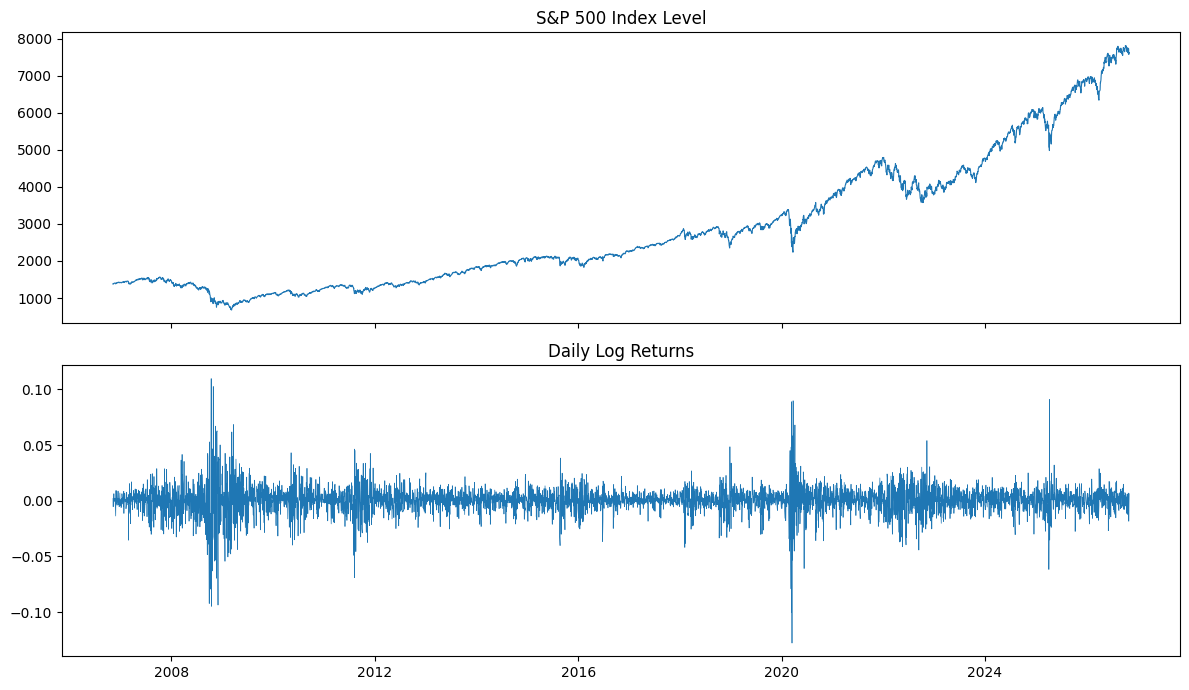

In [5]:
fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
ax[0].plot(prices.index, prices.values, lw=0.8)
ax[0].set_title("S&P 500 Index Level")
ax[1].plot(returns.index, returns.values, lw=0.5)
ax[1].set_title("Daily Log Returns")
plt.tight_layout()
plt.show()

In [6]:
# Scale to percent for better numerical convergence
y = returns * 100

model = sm.tsa.MarkovRegression(
    y,
    k_regimes=2,
    trend="c",
    switching_variance=True
)
result = model.fit(search_reps=20)
print(result.summary())

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)


                        Markov Switching Model Results                        
Dep. Variable:                 Return   No. Observations:                 5026
Model:               MarkovRegression   Log Likelihood               -7012.939
Date:                Mon, 02 Nov 2026   AIC                          14037.878
Time:                        16:21:17   BIC                          14077.012
Sample:                             0   HQIC                         14051.590
                               - 5026                                         
Covariance Type:               approx                                         
                             Regime 0 parameters                              
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0982      0.012      8.103      0.000       0.074       0.122
sigma2         0.4706      0.019     25.224      0.0

In [8]:
params = result.params
P = np.asarray(result.regime_transition).squeeze()  # 2x2 transition matrix
p00, p11 = P[0, 0], P[1, 1]  # diagonal = probability of staying in the same regime

regime_table = pd.DataFrame({
    "Mean (%)": [params["const[0]"], params["const[1]"]],
    "Std Dev (%)": [np.sqrt(params["sigma2[0]"]), np.sqrt(params["sigma2[1]"])],
    "Annualized Mean": [params["const[0]"] * 252, params["const[1]"] * 252],
    "Annualized Vol": [np.sqrt(params["sigma2[0]"] * 252), np.sqrt(params["sigma2[1]"] * 252)],
}, index=["Regime 0", "Regime 1"])

print(f"Transition probability p(0→0): {p00:.4f}")
print(f"Transition probability p(1→1): {p11:.4f}")
regime_table

Transition probability p(0→0): 0.9836
Transition probability p(1→1): 0.9551


,Mean (%),Std Dev (%),Annualized Mean,Annualized Vol
Regime 0,0.098220,0.685971,24.751399,10.889447
Regime 1,-0.140869,2.084985,-35.498941,33.098118


In [9]:
smoothed = result.smoothed_marginal_probabilities
smoothed.columns = ["Regime 0", "Regime 1"]

# Label the higher-variance regime as the "Bear" (high-volatility) regime
high_vol_regime = 0 if params["sigma2[0]"] > params["sigma2[1]"] else 1
bear_prob = smoothed.iloc[:, high_vol_regime]

print("Expected duration (days):")
print(f"  Regime 0: {1 / (1 - p00):.1f}")
print(f"  Regime 1: {1 / (1 - p11):.1f}")
smoothed.tail()

Expected duration (days):
  Regime 0: 61.0
  Regime 1: 22.3


,Regime 0,Regime 1
Date,,
2026-10-27,0.990488,0.009512
2026-10-28,0.980927,0.019073
2026-10-29,0.950529,0.049471
2026-10-30,0.870104,0.129896
2026-11-02,0.877320,0.122680


In [10]:
regime = (bear_prob > 0.5).astype(int).rename("Bear")
share = regime.value_counts(normalize=True).rename({0: "Bull/Calm", 1: "Bear/Volatile"})
print("Share of days in each regime:")
print(share)

Share of days in each regime:
Bear
Bull/Calm       0.738758
Bear/Volatile   0.261242
Name: proportion, dtype: float64


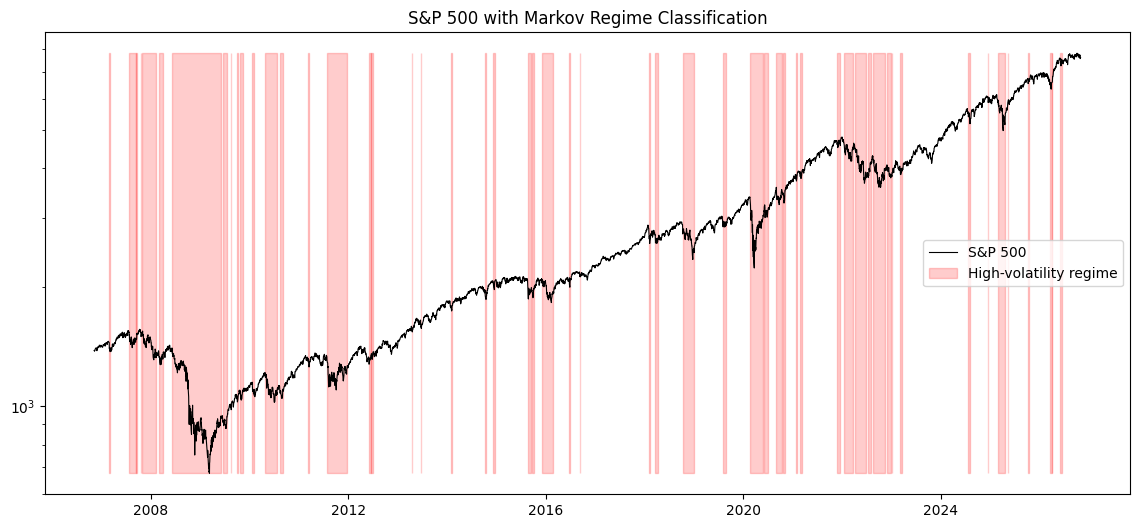

In [11]:
fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(prices.index, prices.values, color="black", lw=0.8, label="S&P 500")

in_bear = regime.reindex(prices.index).fillna(0).astype(bool)
ax.fill_between(prices.index, prices.min(), prices.max(),
                where=in_bear.values, color="red", alpha=0.2,
                label="High-volatility regime")

ax.set_title("S&P 500 with Markov Regime Classification")
ax.set_yscale("log")
ax.legend()
plt.show()